In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts())

print("\nClass names:")
print(data.target_names)

Dataset shape: (569, 30)

Class distribution:
target
1    357
0    212
Name: count, dtype: int64

Class names:
['malignant' 'benign']


In [3]:
y = (data.target == 0).astype(int)

print("0 = Benign, 1 = Malignant")
print(y.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

0 = Benign, 1 = Malignant
target
Benign       357
Malignant    212
Name: count, dtype: int64


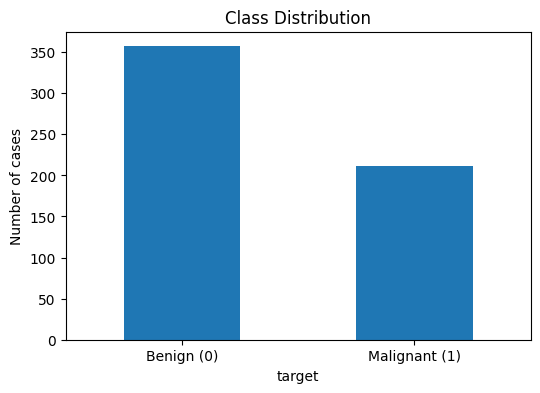

In [4]:
y.value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.xticks([0, 1], ["Benign (0)", "Malignant (1)"], rotation=0)
plt.ylabel("Number of cases")
plt.title("Class Distribution")
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000)
)

model.fit(X_train, y_train)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classifier trained successfully!")

Training samples: 455
Testing samples: 114
Classifier trained successfully!


In [6]:
malignant_index = list(model.classes_).index(1)

y_prob = model.predict_proba(X_test)[:, malignant_index]

for threshold in [0.5, 0.3]:
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
    print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
    print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))


Threshold: 0.5
Accuracy: 0.974
Precision: 0.976
Recall: 0.952
F1-score: 0.964

Threshold: 0.3
Accuracy: 0.965
Precision: 0.952
Recall: 0.952
F1-score: 0.952


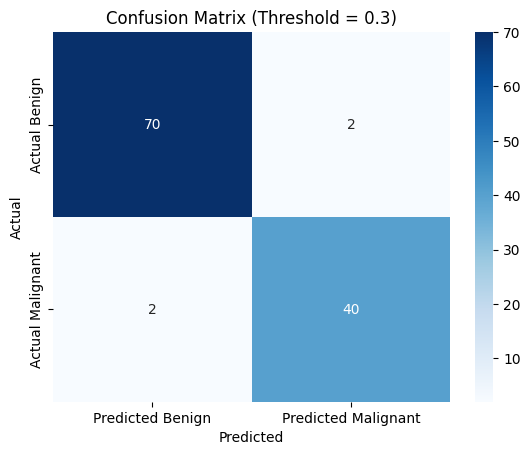

              precision    recall  f1-score   support

      Benign       0.97      0.97      0.97        72
   Malignant       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



In [7]:
threshold = 0.3
y_pred = (y_prob >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Benign", "Predicted Malignant"],
    yticklabels=["Actual Benign", "Actual Malignant"]
)

plt.title(f"Confusion Matrix (Threshold = {threshold})")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

### Why Accuracy Can Be Misleading on Imbalanced Data

Accuracy measures the proportion of all predictions that are correct. However, when one class is much more frequent than another, a model can achieve high accuracy by mainly predicting the majority class.

For example, if 95 out of 100 cases are benign, a classifier that predicts every case as benign achieves 95% accuracy but identifies zero malignant cases. Its recall for the malignant class is 0%.

Therefore, accuracy should not be used alone. Precision, recall, F1-score, and the confusion matrix provide a clearer picture of minority-class performance.

In this task, recall for malignant cases is especially important because false negatives represent malignant cases that the model fails to identify.

The threshold should be selected according to the trade-off between missed malignant cases and false alarms, rather than chosen only to maximize accuracy.

In [8]:

from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score,
    classification_report
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Get probability that each case is malignant (class 1)
y_prob = model.predict_proba(X_test)[:, 1]

# Compare two thresholds
results = []

for threshold in [0.5, 0.3]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1-score": f1_score(y_test, y_pred_threshold)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1-score
       0.5     0.974      0.976   0.952     0.964
       0.3     0.965      0.952   0.952     0.952


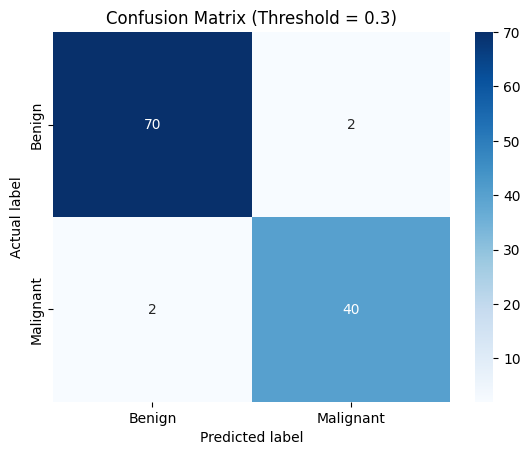

              precision    recall  f1-score   support

      Benign       0.97      0.97      0.97        72
   Malignant       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



In [9]:

# Use 0.3 as an example threshold for comparison
chosen_threshold = 0.3
y_pred = (y_prob >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"Confusion Matrix (Threshold = {chosen_threshold})")
plt.show()

print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))


### Why Accuracy Can Be Misleading on Imbalanced Data

Accuracy measures the proportion of all predictions that are correct. However, it can be misleading when one class is much more common than another.

For example, if a dataset contains 95 benign cases and 5 malignant cases, a model that predicts every case as benign achieves 95% accuracy but identifies none of the malignant cases. Its recall for the malignant class is 0%.

Therefore, precision, recall, F1-score, and the confusion matrix provide additional information about model performance. In this task, malignant recall is particularly important because false negatives represent malignant cases incorrectly predicted as benign.

### Threshold Selection

The default classification threshold is 0.5. A lower threshold, such as 0.3, classifies more cases as malignant. This may improve malignant recall but can also increase false positives and reduce precision.

The threshold should be selected using validation data according to the problem's priorities. The final test set should be used only to evaluate the chosen model and threshold.

**Note:** This dataset is used for educational machine-learning practice and is not intended for medical diagnosis.

## Evaluation and Threshold Selection

### Model Performance

The logistic regression classifier was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. The dataset contains 357 benign and 212 malignant samples, so the class distribution is not equal.

At a threshold of 0.5, the model achieved:
- Accuracy: 97.4%
- Precision: 97.6%
- Malignant recall: 95.2%
- F1-score: 96.4%

At a threshold of 0.3, accuracy was 96.5%, precision was 95.2%, malignant recall remained 95.2%, and F1-score was 95.2%.

### Why Accuracy Can Be Misleading

Accuracy alone may hide poor performance on a minority class. For example, a classifier that predicts every sample as benign in a dataset with 95 benign and 5 malignant samples would achieve 95% accuracy but 0% malignant recall.

Precision, recall, F1-score, and the confusion matrix therefore provide a more complete assessment of classification performance.

### Threshold Selection

The default threshold of 0.5 performed better than 0.3 in this comparison. It achieved higher accuracy, precision, and F1-score, while malignant recall remained the same at 95.2%.

Therefore, 0.5 is the preferred threshold in this comparison. For a rigorous evaluation, threshold selection should be performed on validation data, and the test set should be reserved for the final evaluation.

### Conclusion

The classifier achieved strong performance on the held-out test set. Comparing thresholds demonstrated that lowering the threshold does not always improve recall and may reduce precision. Evaluating multiple metrics helps provide a more balanced understanding of classifier performance.

*This dataset is used for educational machine-learning practice and is not intended for medical diagnosis.*